In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import joblib
import os

# Đọc file dữ liệu
data_path = "../data/processed/clean_data.csv"
if not os.path.exists(data_path):
    data_path = "data/processed/clean_data.csv"

df = pd.read_csv(data_path)
print("Đọc dữ liệu thành công! Kích thước:", df.shape)

Đọc dữ liệu thành công! Kích thước: (10000, 19)


In [7]:
# Chọn 5 đặc trưng hành vi học tập (dựa theo tên cột tiếng Việt từ phần EDA của nhóm)
features = [
    'Tỷ lệ chuyên cần (%)', 
    'Điểm bài tập trung bình', 
    'Điểm kiểm tra ngắn trung bình', 
    'Điểm tham gia học tập', 
    'Điểm dự án'
]

X = df[features]

# Chuẩn hóa dữ liệu bằng StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Đã chuẩn hóa dữ liệu thành công!")
print("Kích thước ma trận sau chuẩn hóa:", X_scaled.shape)

Đã chuẩn hóa dữ liệu thành công!
Kích thước ma trận sau chuẩn hóa: (10000, 5)


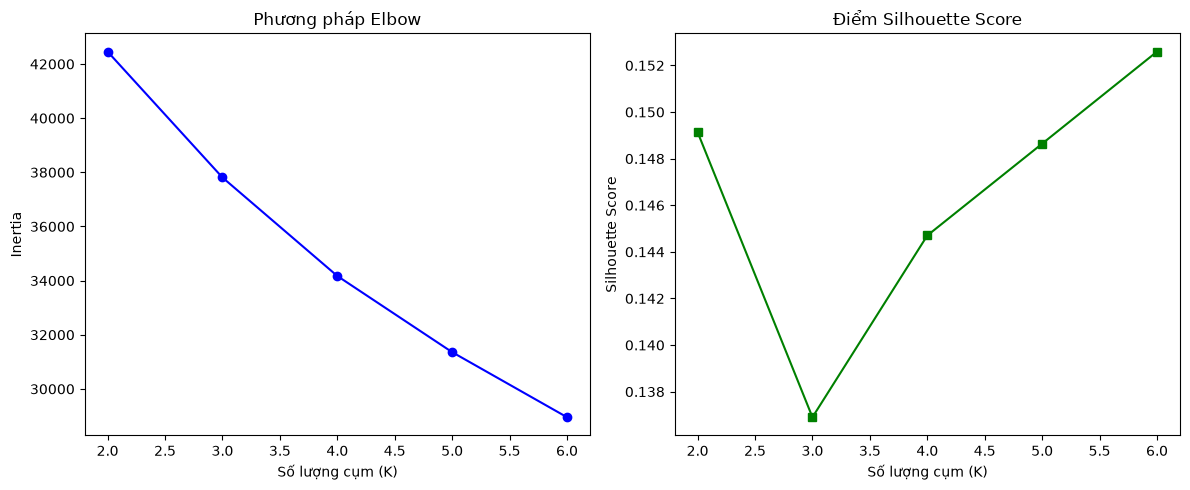

In [8]:
inertia = []
silhouette_scores = []
K_range = range(2, 7)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Vẽ biểu đồ đánh giá
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(K_range, inertia, marker='o', color='b')
plt.xlabel('Số lượng cụm (K)')
plt.ylabel('Inertia')
plt.title('Phương pháp Elbow')

plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette_scores, marker='s', color='g')
plt.xlabel('Số lượng cụm (K)')
plt.ylabel('Silhouette Score')
plt.title('Điểm Silhouette Score')

plt.tight_layout()
plt.show()

In [9]:
# Chọn số cụm K tối ưu (ví dụ K = 4 dựa trên biểu đồ)
optimal_k = 4 

kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

print(f"Đã huấn luyện mô hình K-Means với K = {optimal_k}")
print("Số lượng sinh viên phân bố trong từng cụm:")
print(df['Cluster'].value_counts())

# Lưu pipeline (scaler và model) vào thư mục models/
os.makedirs('../models', exist_ok=True)
joblib.dump(scaler, '../models/scaler.pkl')
joblib.dump(kmeans_final, '../models/kmeans_model.pkl')
print("\nĐã lưu scaler và mô hình thành công vào thư mục models/!")

Đã huấn luyện mô hình K-Means với K = 4
Số lượng sinh viên phân bố trong từng cụm:
Cluster
2    2575
0    2530
3    2457
1    2438
Name: count, dtype: int64

Đã lưu scaler và mô hình thành công vào thư mục models/!


In [10]:
import json

# 1. Viết hàm predict_cluster() để bàn giao cho ứng dụng (dùng khi có dữ liệu sinh viên mới nhập vào)
def predict_cluster(chuyen_can, bt_tb, kt_tb, tham_gia, du_an):
    """
    Hàm nhận các chỉ số hành vi của sinh viên, chuẩn hóa và dự đoán cụm
    """
    # Tạo DataFrame đúng tên các cột đặc trưng đã huấn luyện
    input_data = pd.DataFrame([[chuyen_can, bt_tb, kt_tb, tham_gia, du_an]], columns=features)
    
    # Chuẩn hóa dữ liệu bằng scaler đã lưu
    input_scaled = scaler.transform(input_data)
    
    # Dự đoán cụm bằng mô hình KMeans đã huấn luyện
    cluster_id = kmeans_final.predict(input_scaled)[0]
    return int(cluster_id)

# Ví dụ thử nghiệm gọi hàm dự đoán với một bạn sinh viên giả định:
# (Tỷ lệ chuyên cần, Điểm BT TB, Điểm KT TB, Điểm tham gia, Điểm dự án)
sample_cluster = predict_cluster(85.0, 7.5, 8.0, 8.5, 7.0)
print(f"Ví dụ dự đoán: Sinh viên này thuộc cụm số {sample_cluster}")


# 2. Tính toán hồ sơ cụm (đặc điểm trung bình của từng cụm) và xuất ra file JSON
# Tính trung bình các đặc trưng theo từng Cluster
cluster_profile = df.groupby('Cluster')[features].mean().to_dict(orient='index')

# Chuyển đổi khóa (key) từ số nguyên sang chuỗi (string) để đảm bảo file JSON hợp lệ
cluster_profile_str = {str(k): v for k, v in cluster_profile.items()}

# Tự động tạo thư mục ../models nếu chưa có và lưu file JSON vào đó
os.makedirs('../models', exist_ok=True)
json_path = '../models/cluster_profile.json'

with open(json_path, 'w', encoding='utf-8') as f:
    json.dump(cluster_profile_str, f, ensure_ascii=False, indent=4)

print(f"\nĐã xuất hồ sơ cụm thành công ra file: {json_path}")

Ví dụ dự đoán: Sinh viên này thuộc cụm số 2

Đã xuất hồ sơ cụm thành công ra file: ../models/cluster_profile.json
